In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')





/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


In [2]:
train=pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test=pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")
sample_submission=pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv")

In [3]:
traindf=train.copy()
testdf=test.copy()

In [4]:
print(traindf.isnull().sum()[traindf.isnull().sum() > 0])
print(traindf["satisfaction"].isnull().sum())

Arrival Delay in Minutes    292
dtype: int64
0


In [5]:
missing_count = traindf["Arrival Delay in Minutes"].isnull().sum()
missing_percent = ( missing_count / len(train)) * 100
print("Missing values:", missing_count)
print("Missing percentage:", missing_percent)

Missing values: 292
Missing percentage: 0.041736048082214296


In [6]:
#check duplicates
print("Duplicates in dataset:",traindf.duplicated().sum())
#check id in both dataset
display(traindf["id"].duplicated().sum())
print(test["id"].duplicated().sum())

Duplicates in dataset: 0


np.int64(0)

0


In [7]:
#Numerical Summary of the dataset
display(traindf.describe())
#categorical summary of the dataset
traindf.describe(include='object')

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


,Gender,Customer Type,Type of Travel,Class
count,699635,699635,699635,699635
unique,2,2,2,3
top,Male,Loyal Customer,Business travel,Business
freq,351683,576990,497441,342212


In [8]:
# #numerical columns
# numerical_columnss=traindf.select_dtypes(include="number").columns
# print(numerical_columns)
# #categorical columns
# categorical_columnss=traindf.select_dtypes(include='object').columns
# print(categorical_columns)

In [9]:

# Remove the target column from training features
train_features = traindf.drop(columns=["satisfaction"])

# Get feature column names
train_cols = set(train_features.columns)
test_cols = set(testdf.columns)

# Compare columns
print("Train feature count:", len(train_cols))
print("Test feature count:", len(test_cols))

print("\nColumns present in train but missing in test:")
print(train_cols - test_cols)

print("\nColumns present in test but missing in train:")
print(test_cols - train_cols)

# Final check
if train_cols == test_cols:
    print("\nBoth datasets have the same feature columns.")
else:
    print("\nFeature columns do not match.")



Train feature count: 22
Test feature count: 22

Columns present in train but missing in test:
set()

Columns present in test but missing in train:
set()

Both datasets have the same feature columns.


In [10]:

#compare datatypes
dtype_comparison = pd.DataFrame({
    "Train_dtype": train_features.dtypes,
    "Test_dtype": testdf.dtypes
})

dtype_comparison["Same_dtype"] = (
    dtype_comparison["Train_dtype"] ==
    dtype_comparison["Test_dtype"]
)

display(dtype_comparison)


,Train_dtype,Test_dtype,Same_dtype
id,int64,int64,True
Age,int64,int64,True
Flight Distance,int64,int64,True
Inflight wifi service,int64,int64,True
Departure/Arrival time convenient,int64,int64,True
Ease of Online booking,int64,int64,True
Gate location,int64,int64,True
Food and drink,int64,int64,True
Online boarding,int64,int64,True
Seat comfort,int64,int64,True


In [11]:
print("Same column order:",list(train_features.columns) == list(testdf.columns))

Same column order: True


# Univariate Data Analysis

In [12]:

import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

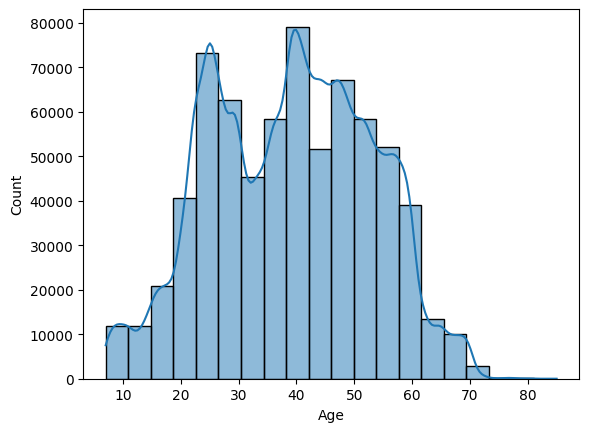

In [13]:
#plot a histogram of age and describe its distribution
sns.histplot(traindf["Age"],bins=20,kde=True)
plt.show()

<Axes: xlabel='Flight Distance', ylabel='Count'>

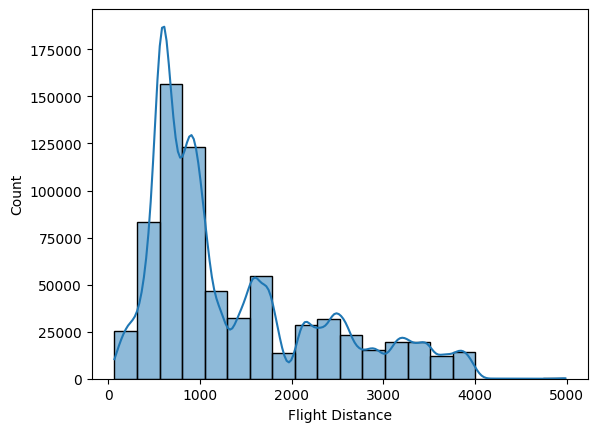

In [14]:
#plot a histogram for flight distance and identify the possible skewness
sns.histplot(traindf['Flight Distance'],bins=20,kde=True)


In [15]:
#check skewness
skew_value = traindf["Flight Distance"].skew()
print("Skewness:", skew_value)
#check mean and median
print("Mean:", traindf["Flight Distance"].mean())
print("Median:", traindf["Flight Distance"].median())

Skewness: 1.0804656071734196
Mean: 1353.7787017516275
Median: 954.0


<Axes: xlabel='Gender', ylabel='count'>

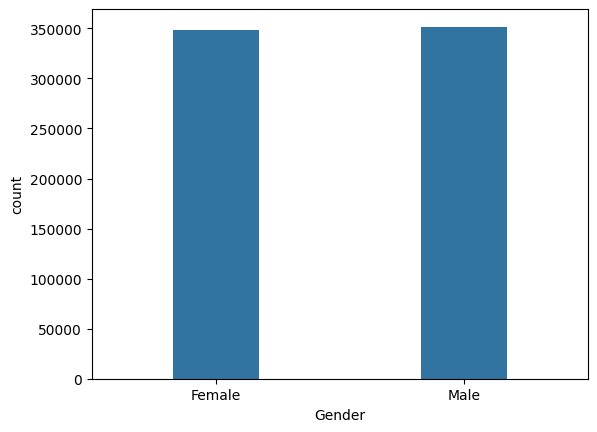

In [16]:
#plot countplot  of Gender
sns.countplot(data=traindf,x="Gender",width=0.35)

<Axes: xlabel='Customer Type', ylabel='count'>

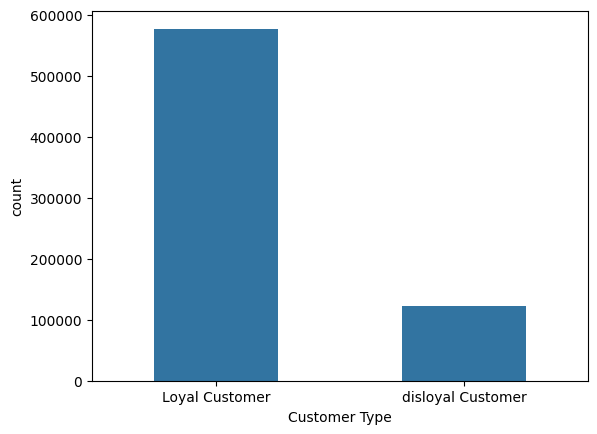

In [17]:
#COUNT PLOT FOR CUSTOMERS TYPE
sns.countplot(data=traindf,x="Customer Type",width=0.5)

<Axes: xlabel='Class', ylabel='count'>

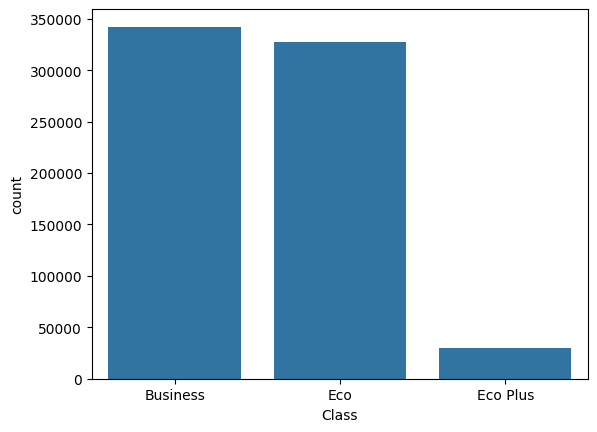

In [18]:
#visualize the number of passengers in each class
sns.countplot(data=traindf,x="Class",order=traindf["Class"].value_counts().index)

<Axes: xlabel='Type of Travel', ylabel='count'>

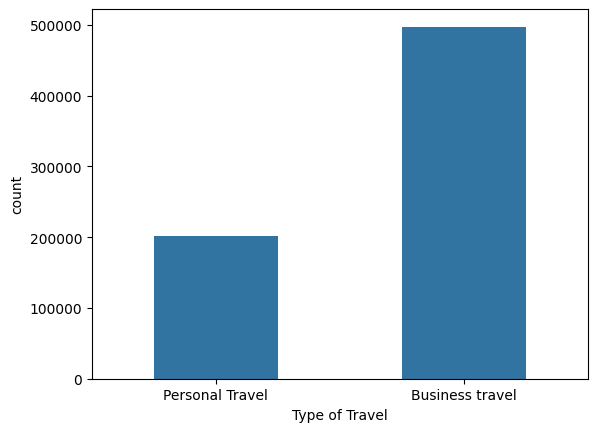

In [19]:

#Count plot of type of travel
sns.countplot(data=traindf,x='Type of Travel',width=0.5)

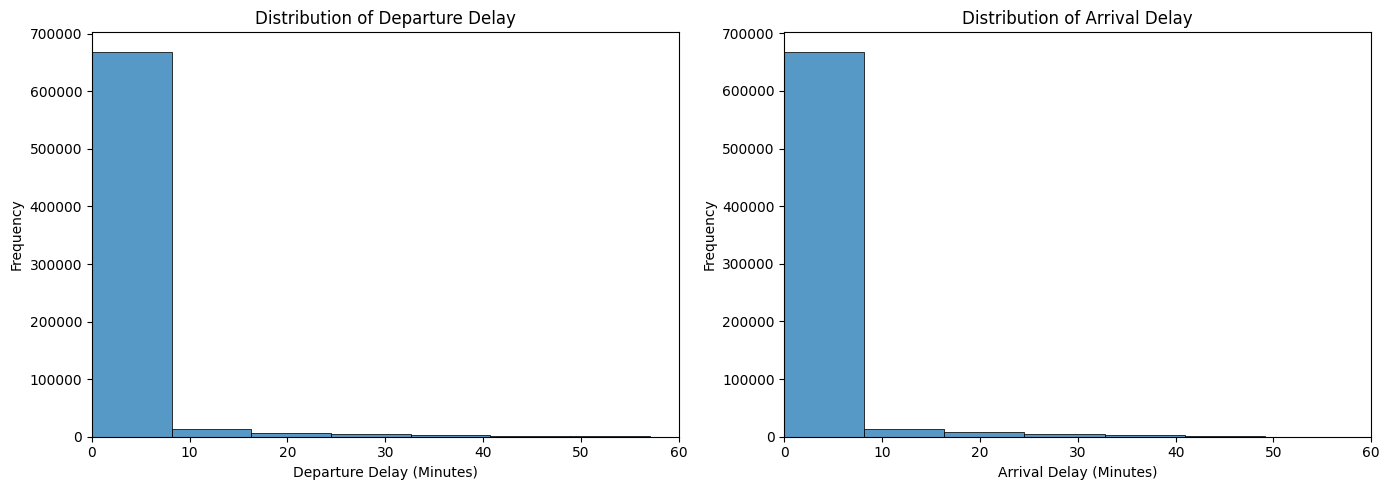

In [20]:
#Create seperate hsitograms for arrival and departure delays
# Create two separate plots
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Departure delay histogram
sns.histplot( data=traindf,x="Departure Delay in Minutes",bins=60,kde=False,ax=axes[0])
axes[0].set_xlim(0,60)
axes[0].set_title("Distribution of Departure Delay")
axes[0].set_xlabel("Departure Delay (Minutes)")
axes[0].set_ylabel("Frequency")

# Arrival delay histogram
sns.histplot(data=traindf,x="Arrival Delay in Minutes",bins=60,kde=False,ax=axes[1])
axes[1].set_xlim(0,60)
axes[1].set_title("Distribution of Arrival Delay")
axes[1].set_xlabel("Arrival Delay (Minutes)")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [21]:
#check skewness and extreme values

delay_cols = [
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]
for col in delay_cols:
    print(f"\n--- {col} ---")
    
    print("Mean:", train[col].mean())
    print("Median:", train[col].median())
    print("Skewness:", train[col].skew())
    print("Minimum:", train[col].min())
    print("Maximum:", train[col].max())
    print("Missing values:", train[col].isnull().sum())
    
    print("95th percentile:", train[col].quantile(0.95))
    print("99th percentile:", train[col].quantile(0.99))



--- Departure Delay in Minutes ---
Mean: 1.1762090232764226
Median: 0.0
Skewness: 12.87216306969923
Minimum: 0
Maximum: 489
Missing values: 0
95th percentile: 7.0
99th percentile: 30.0

--- Arrival Delay in Minutes ---
Mean: 1.1342803173836014
Median: 0.0
Skewness: 13.317512789888804
Minimum: 0.0
Maximum: 491.0
Missing values: 292
95th percentile: 7.0
99th percentile: 28.0


<Axes: xlabel='satisfaction', ylabel='count'>

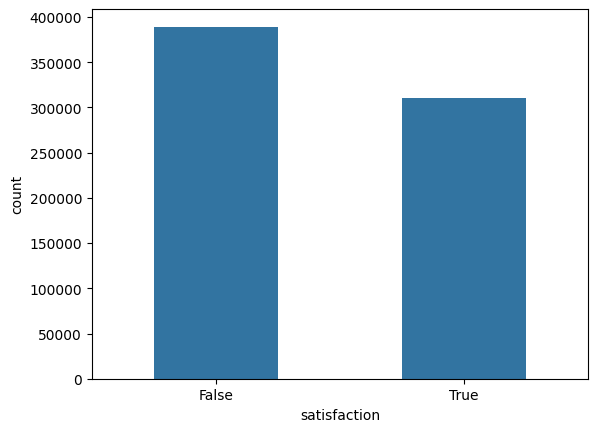

In [22]:
#Plot the count of each `satisfaction` category and show percentages
sns.countplot(data=traindf,x="satisfaction",width=0.5)

<Axes: xlabel='satisfaction', ylabel='Age'>

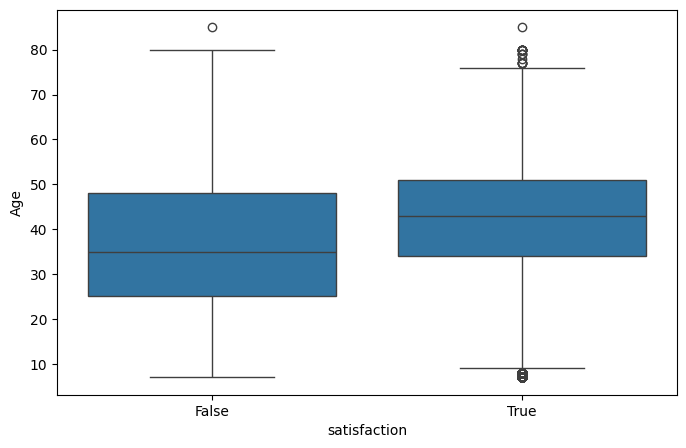

In [23]:
#Age Vs Satisfaction
plt.figure(figsize=(8, 5))
sns.boxplot(data=traindf,x="satisfaction",y="Age")

In [24]:
train.groupby("satisfaction")["Age"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
satisfaction,,,,,,
False,389296,36.504131,35.0,14.858662,7,85
True,310339,42.135220,43.0,11.610186,7,85


<Axes: xlabel='satisfaction', ylabel='Flight Distance'>

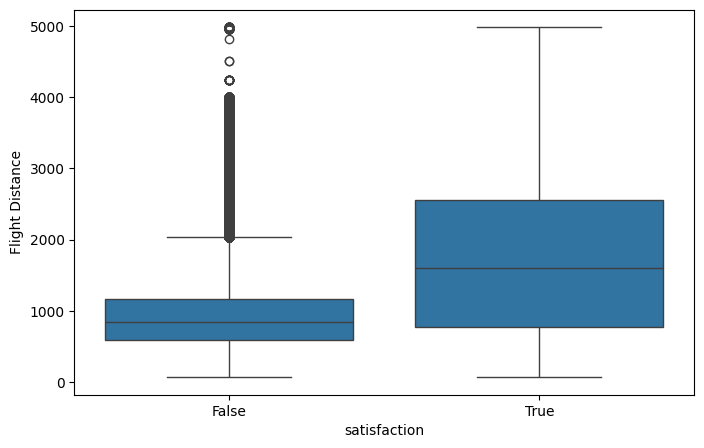

In [25]:
#Fligh Distance Vs Satisfaction
plt.figure(figsize=(8, 5))
sns.boxplot(data=traindf,x="satisfaction",y="Flight Distance")

<Axes: xlabel='Class', ylabel='count'>

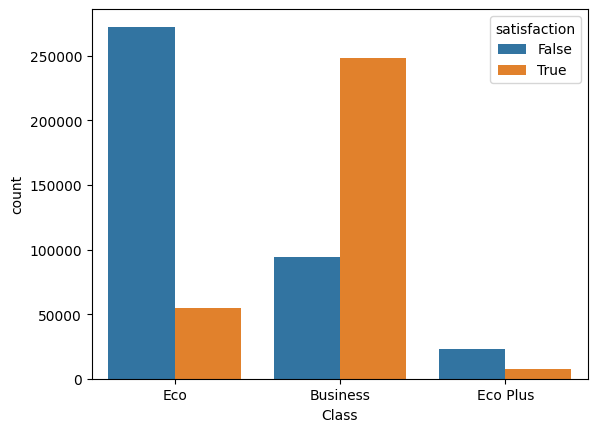

In [26]:
#Count plot for satisfaction by class
sns.countplot(data=traindf,x="Class",hue="satisfaction")

In [27]:

# Satisfaction percentage within each travel class
class_satisfaction = pd.crosstab(
    train["Class"],
    train["satisfaction"],
    normalize="index"
) * 100
print(class_satisfaction.round(2))


satisfaction  False  True 
Class                     
Business      27.47  72.53
Eco           83.24  16.76
Eco Plus      75.78  24.22


<Axes: xlabel='Gender', ylabel='count'>

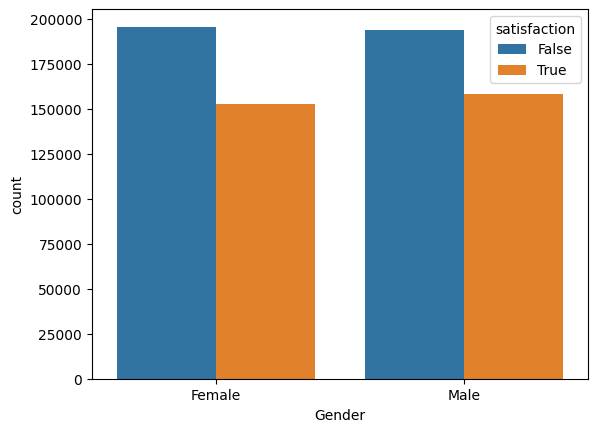

In [28]:
#Satisfaction across gender
sns.countplot(data=traindf,x="Gender",hue="satisfaction")

<Axes: xlabel='Type of Travel', ylabel='count'>

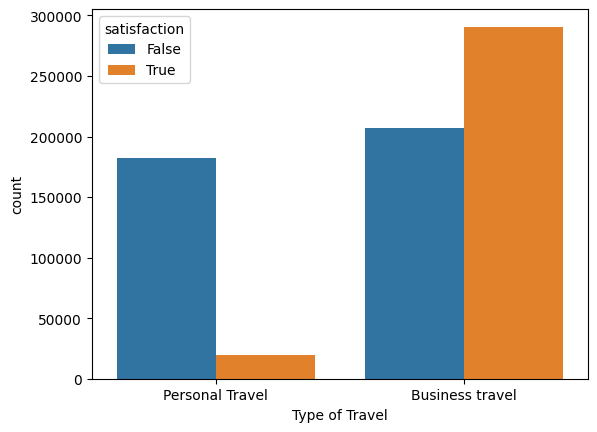

In [29]:

#Satisfaction vs Travel type
sns.countplot(data=traindf,x="Type of Travel",hue="satisfaction")

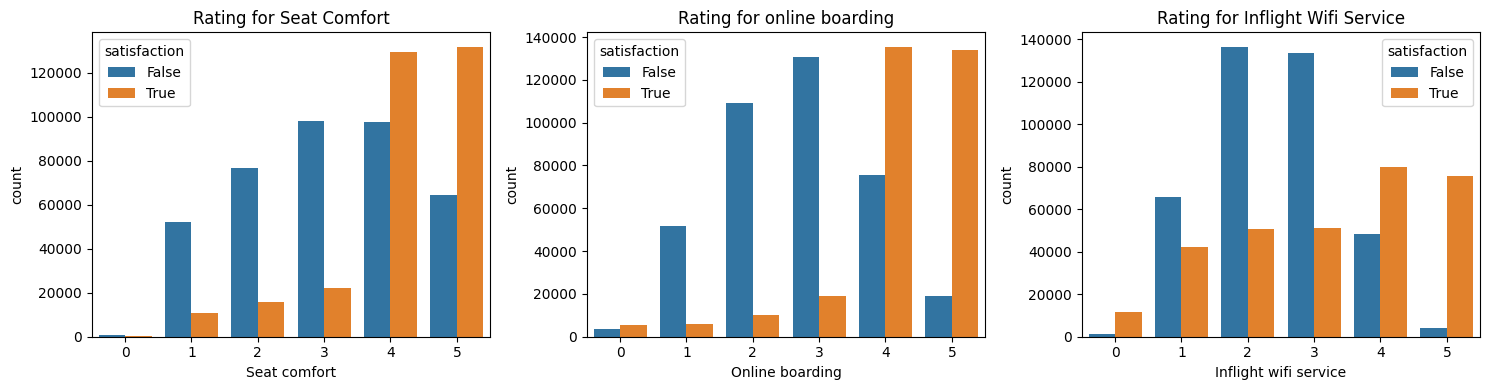

In [30]:
## 1. Create a 1-row, 3-column plot window
plt.figure(figsize=(15, 4))

# 2. First plot: Seat comfort
plt.subplot(1, 3, 1)
sns.countplot(data=traindf, x="Seat comfort", hue="satisfaction")
plt.title("Rating for Seat Comfort")

# 3. Second plot: Online boarding
plt.subplot(1, 3, 2)
sns.countplot(data=traindf, x="Online boarding", hue="satisfaction")
plt.title("Rating for online boarding")

# 4. Third plot: Inflight wifi service
plt.subplot(1, 3, 3)
sns.countplot(data=traindf, x="Inflight wifi service", hue="satisfaction")
plt.title("Rating for Inflight Wifi Service")

# Clean up layout and display
plt.tight_layout()
plt.show()

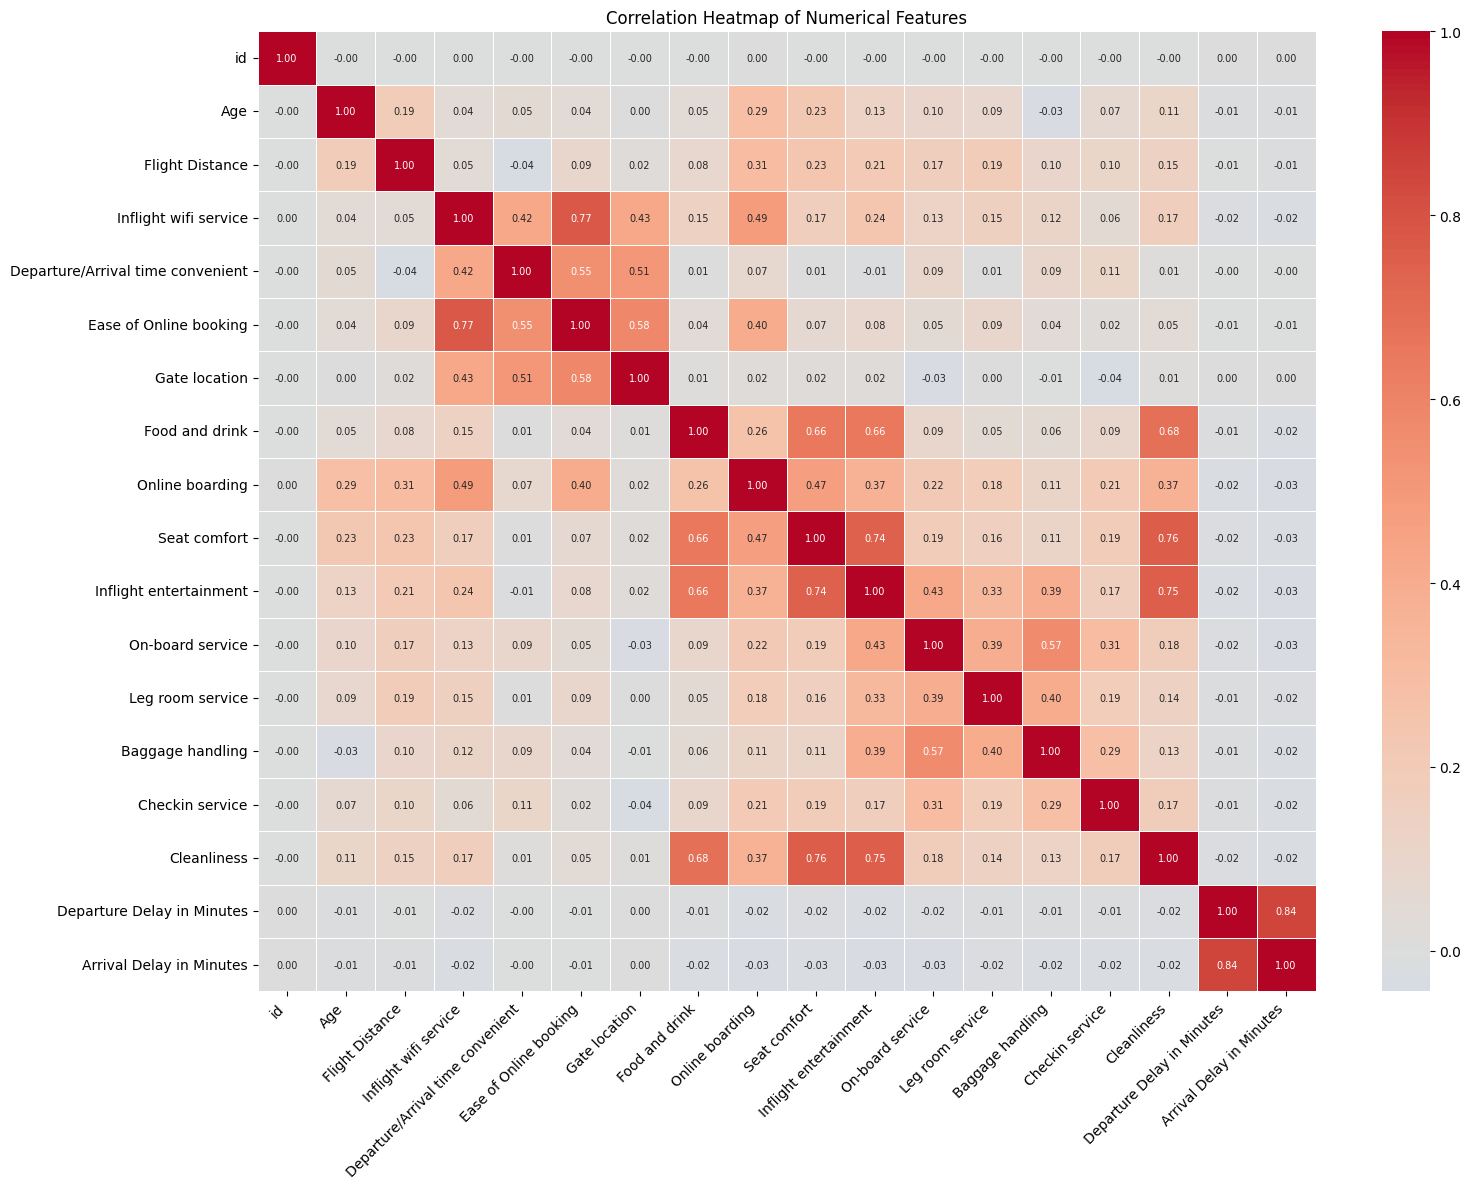

In [31]:
#correlation among numerical columns
corr = traindf.select_dtypes(include="number").corr()
plt.figure(figsize=(16, 12))
sns.heatmap( corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation Heatmap of Numerical Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:
#strongest correlation with satisfaction
print(traindf["satisfaction"].dtype)
print(traindf["satisfaction"].value_counts())

bool
satisfaction
False    389296
True     310339
Name: count, dtype: int64


In [33]:
traindf["satisfaction"] = (
    traindf["satisfaction"].map({False: 0, True: 1})
)

In [34]:
traindf

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699630,699630,57,612,2,1,1,1,1,3,3,...,2,2,4,0,0.0,Female,Loyal Customer,Business travel,Eco,0
699631,699631,30,862,2,2,2,3,4,2,4,...,4,2,4,24,34.0,Female,disloyal Customer,Business travel,Eco,0
699632,699632,49,3148,5,5,5,5,4,4,4,...,5,5,5,0,0.0,Male,Loyal Customer,Business travel,Business,1
699633,699633,61,679,5,2,2,2,5,4,4,...,5,5,1,0,0.0,Female,Loyal Customer,Business travel,Eco,1


In [35]:
#customer satisfaction
customer_satisfaction = (train.groupby("Customer Type")["satisfaction"].value_counts(normalize=True).mul(100).unstack())
print(customer_satisfaction.round(2))

satisfaction       False  True 
Customer Type                  
Loyal Customer     50.49  49.51
disloyal Customer  79.91  20.09


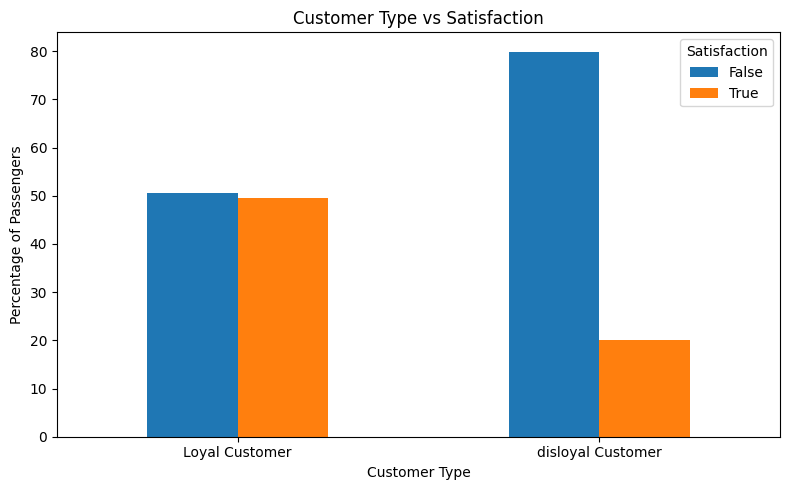

In [36]:
customer_satisfaction.plot( kind="bar", figsize=(8, 5))
plt.title("Customer Type vs Satisfaction")
plt.xlabel("Customer Type")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [37]:
#customer satisfaction
Travel_type_satisfaction = (train.groupby("Type of Travel")["satisfaction"].value_counts(normalize=True).mul(100).unstack())
print(Travel_type_satisfaction.round(2))

satisfaction     False  True 
Type of Travel               
Business travel  41.57  58.43
Personal Travel  90.27   9.73


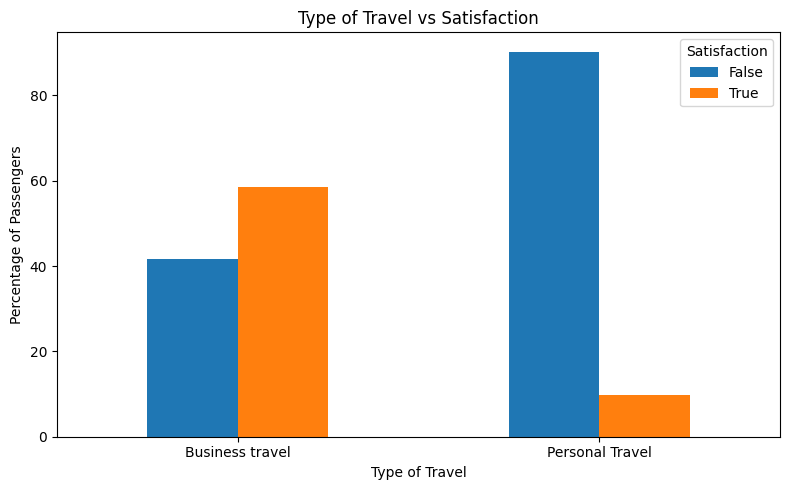

In [38]:
Travel_type_satisfaction.plot( kind="bar", figsize=(8, 5))
plt.title("Type of Travel vs Satisfaction")
plt.xlabel("Type of Travel")
plt.ylabel("Percentage of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [39]:
#Split X and y
X = traindf.drop(columns=["satisfaction","id"])
y = traindf["satisfaction"].astype(int)

In [40]:
#train Test split 
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

In [41]:
median_delay = X_train["Arrival Delay in Minutes"].median()

X_train["Arrival Delay in Minutes"] = (
    X_train["Arrival Delay in Minutes"].fillna(median_delay)
)
X_test["Arrival Delay in Minutes"] = (
    X_test["Arrival Delay in Minutes"].fillna(median_delay)
)

In [42]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


In [43]:
categorical_columns = X_train.select_dtypes( include=["object", "category"]).columns.tolist()
numerical_columns = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Numerical columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [44]:
for col in categorical_columns:
    print(col, ":", X_train[col].unique())

Gender : ['Male' 'Female']
Customer Type : ['Loyal Customer' 'disloyal Customer']
Type of Travel : ['Business travel' 'Personal Travel']
Class : ['Business' 'Eco' 'Eco Plus']


# One hot encoding

In [45]:
#One hot encoding
X_train = pd.get_dummies(X_train,columns=categorical_columns, dtype=int)
X_test = pd.get_dummies(X_test,columns=categorical_columns,dtype=int)

In [46]:
X_train

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
159366,50,2454,1,1,1,1,4,5,5,5,...,29.0,0,1,1,0,1,0,1,0,0
659958,54,1846,1,2,2,2,1,2,1,1,...,0.0,0,1,1,0,1,0,0,1,0
434666,31,1678,1,3,2,2,4,2,4,4,...,0.0,1,0,1,0,0,1,0,1,0
427957,22,759,4,4,5,4,5,5,5,5,...,0.0,1,0,0,1,1,0,0,1,0
409049,21,983,2,2,2,1,3,2,5,3,...,0.0,0,1,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210407,54,2611,3,3,5,3,3,5,5,5,...,0.0,0,1,1,0,1,0,1,0,0
369339,42,3563,2,2,2,2,2,5,4,5,...,0.0,0,1,1,0,1,0,1,0,0
368516,54,972,3,5,3,3,1,3,1,1,...,21.0,0,1,1,0,0,1,0,1,0
484078,38,1399,4,1,1,1,3,3,3,3,...,0.0,1,0,1,0,1,0,1,0,0


In [47]:
X_test.columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'Gender_Female', 'Gender_Male', 'Customer Type_Loyal Customer',
       'Customer Type_disloyal Customer', 'Type of Travel_Business travel',
       'Type of Travel_Personal Travel', 'Class_Business', 'Class_Eco',
       'Class_Eco Plus'],
      dtype='object')

In [48]:
print(X_train.columns.equals(X_test.columns))

True


In [49]:
print("Number of features:", X_train.shape[1])
print(X_train.columns.tolist())

Number of features: 26
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_Female', 'Gender_Male', 'Customer Type_Loyal Customer', 'Customer Type_disloyal Customer', 'Type of Travel_Business travel', 'Type of Travel_Personal Travel', 'Class_Business', 'Class_Eco', 'Class_Eco Plus']


In [50]:
#decide which features to keep and whcih to drop through correlation
correlation = pd.concat([X_train, y_train.rename("satisfaction")], axis=1).corr(numeric_only=True)["satisfaction"].drop("satisfaction")
print(correlation.abs().sort_values(ascending=False))

Online boarding                      0.560648
Class_Business                       0.554866
Class_Eco                            0.521078
Type of Travel_Personal Travel       0.443941
Type of Travel_Business travel       0.443941
Inflight entertainment               0.430358
Seat comfort                         0.401507
Flight Distance                      0.369875
On-board service                     0.346747
Cleanliness                          0.339036
Leg room service                     0.329599
Inflight wifi service                0.291773
Baggage handling                     0.258175
Checkin service                      0.249790
Customer Type_disloyal Customer      0.225857
Customer Type_Loyal Customer         0.225857
Food and drink                       0.217217
Age                                  0.202721
Ease of Online booking               0.191439
Class_Eco Plus                       0.085742
Arrival Delay in Minutes             0.051036
Departure/Arrival time convenient 

# Feature Scaling

In [51]:

from sklearn.preprocessing import StandardScaler
numerical_columns = [
col for col in numerical_columns
    if col in X_train.columns
]

In [52]:
scaler = StandardScaler()
X_train[numerical_columns]= scaler.fit_transform( X_train[numerical_columns])
X_test[numerical_columns] = scaler.transform( X_test[numerical_columns])

In [53]:
X_train

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
159366,0.797252,1.152246,-1.388973,-1.461886,-1.363365,-1.605454,0.564319,1.269192,1.121493,1.181528,...,4.870294,0,1,1,0,1,0,1,0,0
659958,1.087289,0.515421,-1.388973,-0.783909,-0.611501,-0.808233,-1.742448,-1.059170,-2.014683,-1.876132,...,-0.197775,0,1,1,0,1,0,0,1,0
434666,-0.580428,0.339456,-1.388973,-0.105931,-0.611501,-0.808233,0.564319,-1.059170,0.337449,0.417113,...,-0.197775,1,0,1,0,0,1,0,1,0
427957,-1.233012,-0.623114,0.953554,0.572046,1.644091,0.786207,1.333242,1.269192,1.121493,1.181528,...,-0.197775,1,0,0,1,1,0,0,1,0
409049,-1.305522,-0.388494,-0.608130,-0.783909,-0.611501,-1.605454,-0.204603,-1.059170,1.121493,-0.347302,...,-0.197775,0,1,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210407,1.087289,1.316689,0.172712,-0.105931,1.644091,-0.011013,-0.204603,1.269192,1.121493,1.181528,...,-0.197775,0,1,1,0,1,0,1,0,0
369339,0.217176,2.313824,-0.608130,-0.783909,-0.611501,-0.808233,-0.973525,1.269192,0.337449,1.181528,...,-0.197775,0,1,1,0,1,0,1,0,0
368516,1.087289,-0.400016,0.172712,1.250024,0.140363,-0.011013,-1.742448,-0.283049,-2.014683,-1.876132,...,3.472206,0,1,1,0,0,1,0,1,0
484078,-0.072862,0.047228,0.953554,-1.461886,-1.363365,-1.605454,-0.204603,-0.283049,-0.446595,-0.347302,...,-0.197775,1,0,1,0,1,0,1,0,0


In [54]:
X_train.columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'Gender_Female', 'Gender_Male', 'Customer Type_Loyal Customer',
       'Customer Type_disloyal Customer', 'Type of Travel_Business travel',
       'Type of Travel_Personal Travel', 'Class_Business', 'Class_Eco',
       'Class_Eco Plus'],
      dtype='object')

In [55]:
X_test

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Arrival Delay in Minutes,Gender_Female,Gender_Male,Customer Type_Loyal Customer,Customer Type_disloyal Customer,Type of Travel_Business travel,Type of Travel_Personal Travel,Class_Business,Class_Eco,Class_Eco Plus
13744,-0.942975,-0.617877,0.172712,-0.105931,0.140363,-0.011013,-1.742448,-0.283049,-2.014683,-1.876132,...,-0.197775,1,0,0,1,1,0,0,1,0
580104,0.869761,0.047228,1.734397,0.572046,0.892227,1.583427,0.564319,0.493072,0.337449,-1.876132,...,-0.197775,1,0,1,0,1,0,1,0,0
438232,-0.217880,0.846402,-1.388973,0.572046,0.892227,0.786207,-1.742448,0.493072,-1.230639,-1.876132,...,1.200313,1,0,1,0,1,0,1,0,0
7317,-0.870465,0.968949,0.172712,-0.105931,0.140363,-0.011013,0.564319,0.493072,0.337449,0.417113,...,-0.197775,1,0,1,0,1,0,1,0,0
310446,-0.580428,0.990945,0.953554,0.572046,0.892227,-0.011013,0.564319,0.493072,0.337449,0.417113,...,-0.197775,0,1,0,1,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267691,0.362195,1.268508,-1.388973,-1.461886,-1.363365,-1.605454,0.564319,-0.283049,-0.446595,-0.347302,...,-0.197775,1,0,1,0,1,0,1,0,0
575440,0.869761,-0.610545,0.172712,0.572046,0.140363,-0.011013,0.564319,1.269192,-0.446595,-1.111717,...,-0.197775,1,0,1,0,0,1,0,1,0
115128,2.029912,-0.848307,-0.608130,0.572046,-0.611501,-0.808233,1.333242,0.493072,0.337449,1.181528,...,-0.197775,1,0,1,0,0,1,0,1,0
184582,0.434704,0.282895,1.734397,1.250024,1.644091,1.583427,-0.204603,-0.283049,0.337449,-0.347302,...,-0.197775,1,0,1,0,1,0,1,0,0


In [56]:
numerical_columns

['Age',
 'Flight Distance',
 'Inflight wifi service',
 'Departure/Arrival time convenient',
 'Ease of Online booking',
 'Gate location',
 'Food and drink',
 'Online boarding',
 'Seat comfort',
 'Inflight entertainment',
 'On-board service',
 'Leg room service',
 'Baggage handling',
 'Checkin service',
 'Cleanliness',
 'Departure Delay in Minutes',
 'Arrival Delay in Minutes']

# Logistic Regression

In [57]:
from sklearn.linear_model import LogisticRegression 


In [58]:
model_lr=LogisticRegression()
model_lr.fit(X_train,y_train)

LogisticRegression()

In [59]:
y_pred_lr=model_lr.predict(X_test)

In [60]:
y_pred_lr

array([0, 1, 0, ..., 0, 1, 0])

In [61]:
y_test

13744     0
580104    1
438232    0
7317      1
310446    0
         ..
267691    1
575440    0
115128    0
184582    1
445064    0
Name: satisfaction, Length: 139927, dtype: int64

In [62]:
print("Actual values:")
print(y_test.head(10).values)
print("Predicted values:")
print(y_pred_lr[:10])

Actual values:
[0 1 0 1 0 0 0 0 0 0]
Predicted values:
[0 1 0 1 1 0 0 0 0 0]


In [63]:
from sklearn.metrics import (
    accuracy_score,precision_score,recall_score,f1_score,
    classification_report,
    confusion_matrix
)
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precison:",precision_score(y_test,y_pred_lr))
print("Recall:",recall_score(y_test,y_pred_lr))
print("F1 Score:",f1_score(y_test,y_pred_lr))

Accuracy: 0.8780864307817647
Precison: 0.8748438462947848
Recall: 0.8462170522652575
F1 Score: 0.8602923713197658


In [64]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89     77859
           1       0.87      0.85      0.86     62068

    accuracy                           0.88    139927
   macro avg       0.88      0.87      0.88    139927
weighted avg       0.88      0.88      0.88    139927


Confusion Matrix:
[[70345  7514]
 [ 9545 52523]]


In [65]:
print("Training shape:", X_train.shape)
print("Evaluation shape:", X_test.shape)

print("\nActual labels:")
print(y_test.value_counts())

print("\nPredicted labels:")
print(pd.Series(y_pred_lr).value_counts())

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Training shape: (559708, 26)
Evaluation shape: (139927, 26)

Actual labels:
satisfaction
0    77859
1    62068
Name: count, dtype: int64

Predicted labels:
0    79890
1    60037
Name: count, dtype: int64

Confusion matrix:
[[70345  7514]
 [ 9545 52523]]


In [66]:
print("Training columns:")
print(X_train.columns.tolist())

print("\nTarget column:")
print(y_train.name)

Training columns:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender_Female', 'Gender_Male', 'Customer Type_Loyal Customer', 'Customer Type_disloyal Customer', 'Type of Travel_Business travel', 'Type of Travel_Personal Travel', 'Class_Business', 'Class_Eco', 'Class_Eco Plus']

Target column:
satisfaction


In [67]:
#Cross validation for the Logistic regression Model
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000)
cv_scores = cross_val_score(model_lr,X_train,y_train,cv=5,scoring="accuracy",n_jobs=-1)
print("Accuracy for each fold:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Accuracy for each fold: [0.87965196 0.87704347 0.87801719 0.87978489 0.8781501 ]
Mean CV accuracy: 0.8785295205284587
Standard deviation: 0.0010440897653987873


# Decision Tree

In [68]:
from sklearn.tree import DecisionTreeClassifier

In [69]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)